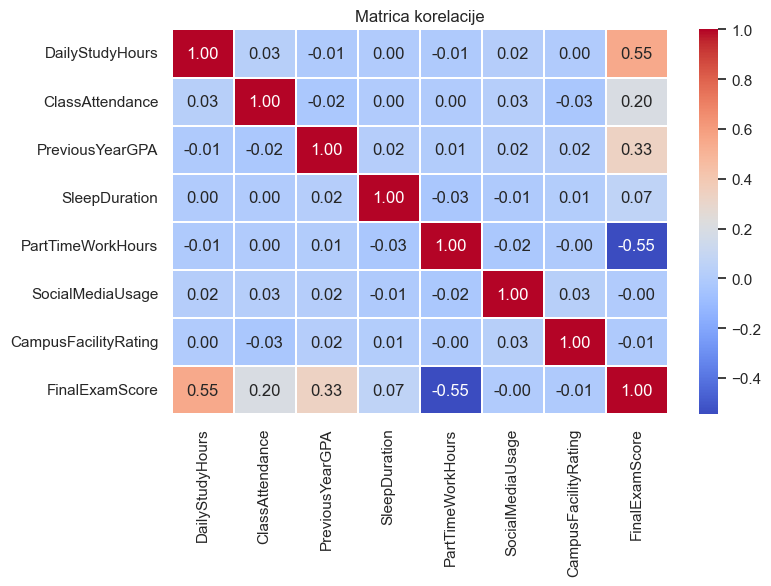

U matrici korelacije ne postoje nigde dve nezavisne promenljive sa jakom korelacijom, a ni dve nezavisne promenljive sa savrsenom kolinearnoscu, pa zato necu obrisati nijednu kolonu.
DailyStudyHours
Test t daje p-vrednost 5.566801279198742e-169, veza je linearna.
------------------------------------------------------------
ClassAttendance
Test t daje p-vrednost 3.110895238012306e-30, veza je linearna.
------------------------------------------------------------
PreviousYearGPA
Test t daje p-vrednost 2.408839974135577e-84, veza je linearna.
------------------------------------------------------------
SleepDuration
Test t daje p-vrednost 0.012471771419515628, veza je linearna.
------------------------------------------------------------
PartTimeWorkHours
Test t daje p-vrednost 2.9225717640015047e-170, veza je linearna.
------------------------------------------------------------
SocialMediaUsage
Test t daje p-vrednost 0.021365222580051826, veza je linearna.
------------------------------

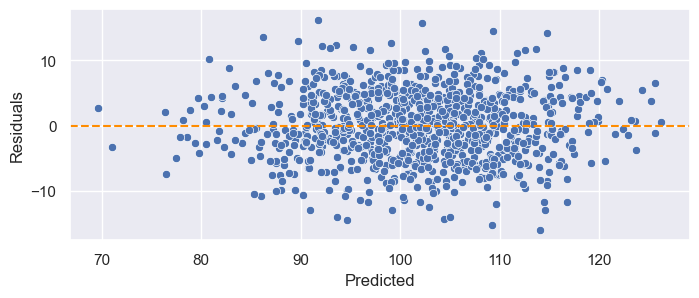


Na grafiku reziduala ne postoji jasan sablon, pa mogu da pretpostavim da su greske nezavisne.

Pretpostavka: Nezavisnost grešaka
Test Durbin–Watson daje vrednost 1.5494890994895698 
Pretpostavka nezavisnosti gresaka vazi , jer ne postoji bitna autokorelacija izmedju reziduala.


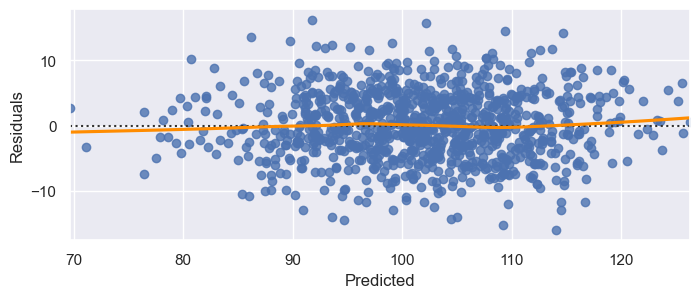


Pretpostavka: Srednja vrednost nula za greske
Metoda LOWESS.
Na osnovu grafika greske ne odstupaju mnogo od nule, pa pretpostavka vazi.


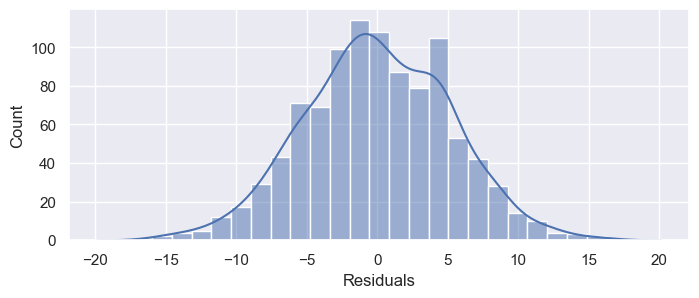


Na grafiku uocavamo nesto sto lici na Gausovu zvonastu krivu pa mogu da pretpostavim da su greske normalno distribuirane.

Pretpostavka: Normalnost grešaka
Test Anderson–Darling daje p-vrednost 0.5185415369419283 
Pretpostavka normalnosti gresaka vazi,jer p-vrednost nije manja od 0,05,sto znaci da su reziduali normalno distribuirani.


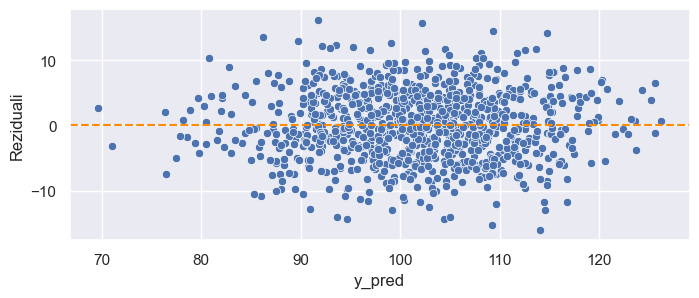


Na grafiku reziduala ne postoji jasan sablon, pa mogu da pretpostavim da vazi jednaka varijansa.
Pretpostavka: Jednaka varijansa
Test Goldfeld–Quandt daje p-vrednost 0.9259563600097096 
Pretpostavka jednake varijanse vazi, jer p-vrednost nije manja 0,05.

 adj_r2  = 0.742


In [1]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sb
import pandas as pd
import statsmodels.api as sm

matplotlib.rcParams['figure.figsize'] = (8, 3)
sb.set(font_scale=1.)

df = pd.read_csv('data/train.csv', sep=',')

# provera nedostajucih vrednosti
def check_for_missing_values(df):
    missing_values = df.isna().sum()
    non_zero_missing = missing_values[missing_values != 0]
    non_zero_missing_percentage = (non_zero_missing / len(df)) * 100
    return pd.DataFrame({
        'N missing': non_zero_missing,
        '% missing': non_zero_missing_percentage
    })
df_fixed = df.drop(columns=['PreferredStudyTemperature'])

# popunjavanje nedostajucih podataka srednjom vrednoscu
def fillna_mean(df, col_name):
    df_copy = df.copy()
    col_mean = df_copy[col_name].mean()
    df_copy[col_name] = df[col_name].fillna(col_mean)
    return df_copy
df_fixed = fillna_mean(df_fixed, 'SleepDuration')
df_fixed = fillna_mean(df_fixed, 'SocialMediaUsage')
df_fixed = fillna_mean(df_fixed, 'CampusFacilityRating')

# pravljenje modela
x = df_fixed.drop(columns=['FinalExamScore'])
y = df_fixed['FinalExamScore']
x_with_const = sm.add_constant(x)
train_model = sm.OLS(y, x_with_const).fit()

# matrica korelacije
plt.figure(figsize=(8,5))
correlation_matrix = df_fixed.corr()
sb.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.1)
plt.title('Matrica korelacije')
plt.show()
print("U matrici korelacije ne postoje nigde dve nezavisne promenljive sa jakom korelacijom, a ni dve nezavisne promenljive sa savrsenom kolinearnoscu, pa zato necu obrisati nijednu kolonu.")

# t-test za linearnost
alpha = 0.05
for var in x.columns:
    p_value = train_model.pvalues[var]

    print(f"{var}")

    if p_value < alpha:
        print(
            f"Test t daje p-vrednost {p_value}, "
            "veza je linearna."
        )
    else:
        print(
            f"Test t daje p-vrednost {p_value},  "
            "veza je mozda nelinearna, a mozda i linearna."
        )

    print("-" * 60)

# racunanje reziduala
def calculate_residuals(model, features, labels):
    y_pred = model.predict(features)
    df_results = pd.DataFrame({'Actual': labels, 'Predicted': y_pred})
    df_results['Residuals'] = abs(df_results['Actual']) - abs(df_results['Predicted'])
    return df_results

# grafik reziduala
df_results = calculate_residuals(train_model, x_with_const, y)
df_results.head()
sb.scatterplot(x='Predicted', y='Residuals', data=df_results)
plt.axhline(y=0, color='darkorange', linestyle='--')
plt.show()
print("\nNa grafiku reziduala ne postoji jasan sablon, pa mogu da pretpostavim da su greske nezavisne.")

# Durbin–Watson statisticki test za nezavisnost gresaka
from statsmodels.stats.stattools import durbin_watson
dw_value = durbin_watson(df_results['Residuals'])
print("\nPretpostavka: Nezavisnost grešaka")
print(
    f"Test Durbin–Watson daje vrednost {dw_value} ",
    end=""
)
if dw_value < 1.5:
    print(
        "\nPretpostavka nezavisnosti gresaka ne vazi, zbog pozitivne autokorelacije reziduala."
    )
elif dw_value > 2.5:
    print(
        "\nPretpostavka nezavisnosti gresaka ne vazi, zbog negativne autokorelacije reziduala."
    )
else:
    print(
        "\nPretpostavka nezavisnosti gresaka vazi , jer ne postoji bitna autokorelacija izmedju reziduala."
    )

# grafik reziduala i provera srednje vrednosti gresaka
df_results['Residuals'].mean()
sb.residplot(data=df_results, x='Predicted', y='Residuals', lowess=True,  line_kws={'color': 'darkorange'})
plt.show()
print(
        "\nPretpostavka: Srednja vrednost nula za greske"
        "\nMetoda LOWESS.\nNa osnovu grafika greske ne odstupaju mnogo od nule, pa pretpostavka vazi."
    )

# histogram reziduala
sb.histplot(df_results['Residuals'], kde=True, kde_kws=dict(cut=3))
plt.show()
print("\nNa grafiku uocavamo nesto sto lici na Gausovu zvonastu krivu pa mogu da pretpostavim da su greske normalno distribuirane.")
from statsmodels.stats.diagnostic import normal_ad

# Anderson–Darlingov statisticki test za normalnost gresaka
p_value = normal_ad(df_results['Residuals'])[1]
print("\nPretpostavka: Normalnost grešaka")
print(f"Test Anderson–Darling daje p-vrednost {p_value} ", end="")
if p_value < alpha:
    print(
        "\nPretpostavka normalnosti gresaka ne vazi,"
        "jer je p-vrednost manja od 0,05,"
        "sto znaci da reziduali nisu normalno distribuirani."
    )
else:
    print(
        "\nPretpostavka normalnosti gresaka vazi,"
        "jer p-vrednost nije manja od 0,05,"
        "sto znaci da su reziduali normalno distribuirani."
    )

# grafik reziduala
sb.scatterplot(x='Predicted', y='Residuals', data=df_results)
plt.axhline(y=0, color='darkorange', linestyle='--')
plt.ylabel('Reziduali')
plt.xlabel('y_pred')
plt.show()
print("\nNa grafiku reziduala ne postoji jasan sablon, pa mogu da pretpostavim da vazi jednaka varijansa.")

##Goldfeld–Quandtov statisticki test za jednake varijanse
x_with_const = sm.add_constant(x)
p_value = sm.stats.het_goldfeldquandt(df_results['Residuals'], x_with_const)[1]
print("Pretpostavka: Jednaka varijansa")
print(f"Test Goldfeld–Quandt daje p-vrednost {p_value:} ", end="")
if p_value < alpha:
    print(
        "\nPretpostavka jednake varijanse ne vazi, "
        "jer je p-vrednost manja od 0,05."
    )
else:
    print(
        "\nPretpostavka jednake varijanse vazi, "
        "jer p-vrednost nije manja 0,05."
    )

# Model za test skup
dftest = pd.read_csv('data/test.csv', sep=',')

dftest_fixed = dftest.drop(columns=['PreferredStudyTemperature'])

dftest_fixed['SleepDuration'] = dftest_fixed['SleepDuration'].fillna(
    df_fixed['SleepDuration'].mean()
)
dftest_fixed['SocialMediaUsage'] = dftest_fixed['SocialMediaUsage'].fillna(
    df_fixed['SocialMediaUsage'].mean()
)
dftest_fixed['CampusFacilityRating'] = dftest_fixed['CampusFacilityRating'].fillna(
    df_fixed['CampusFacilityRating'].mean()
)

# X i y za test podatke
X_test = dftest_fixed.drop(columns=['FinalExamScore'])
y_test = dftest_fixed['FinalExamScore']

X_test_const = sm.add_constant(X_test)

# predikcija
y_pred_test = train_model.predict(X_test_const)

# R^2 i prilagođeni R^2 nad test skupom pre sredjivanja podataka ,kod preuzet sa ChatGpt-a za metriku
from sklearn.metrics import r2_score

r2_test = r2_score(y_test, y_pred_test)

n = X_test.shape[0]
p = X_test.shape[1]

adj_r2_test = 1 - (1 - r2_test) * (n - 1) / (n - p - 1)

# R^2 i prilagođeni R^2 nad trening skupom sa sredjenim podacima, izbacena jos jedna kolona zbog t-testa
x_no_fac = df_fixed.drop(columns=['FinalExamScore', 'CampusFacilityRating'])
y = df_fixed['FinalExamScore']

x_no_fac_const = sm.add_constant(x_no_fac)
model_no_fac = sm.OLS(y, x_no_fac_const).fit()

y_pred_train_no_fac = model_no_fac.predict(x_no_fac_const)

r2_train_no_fac = r2_score(y, y_pred_train_no_fac)

n_train = x_no_fac.shape[0]
p_train = x_no_fac.shape[1]

adj_r2_train_no_fac = 1 - (1 - r2_train_no_fac) * (n_train - 1) / (n_train - p_train - 1)

# R^2 i prilagođeni R^2 nad test skupom sa sredjenim podacima, izbacena jos jedna kolona zbog t-testa iz trening modela
X_test_no_fac = dftest_fixed.drop(columns=['FinalExamScore', 'CampusFacilityRating'])
X_test_no_fac_const = sm.add_constant(X_test_no_fac)

y_pred_test_no_fac = model_no_fac.predict(X_test_no_fac_const)

r2_test_no_fac = r2_score(y_test, y_pred_test_no_fac)

n_test = X_test_no_fac.shape[0]
p_test = X_test_no_fac.shape[1]

adj_r2_test_no_fac = 1 - (1 - r2_test_no_fac) * (n_test - 1) / (n_test - p_test - 1)

print(f"\n adj_r2  = {adj_r2_test_no_fac:.3f}")

proveraoverfitunderfit = adj_r2_train_no_fac - adj_r2_test_no_fac




